# Literature Positioning: Modality-Set Flexibility and Reliability-Awareness

This notebook positions selected multimodal biometric fusion approaches
according to two dimensions:

- **Modality-Set Flexibility (MSF):** The ability of a fusion approach
  to accommodate different modality configurations.
- **Reliability-Awareness (RA):** The extent to which quality, operating
  context, and reliability information influence the fusion process.

The resulting two-dimensional plot divides the literature into four
conceptual regions.

### 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

### 2. Literature Classification and Scoring

Each approach is represented using five attributes:

- S: Modality-set variability.
- G: Breadth of supported modality configurations.
- Q: Use of sample-quality measures.
- C: Use of operating context.
- R: Use of reliability or confidence estimates.

*The reference numbers follow citation order*

In [2]:
papers = {
    "Kryszczuk":    dict(NUM=4,  S=0, G=0.0, Q=1.0, C=0.0, R=1.0),
    "Soleymani":    dict(NUM=5,  S=0, G=0.0, Q=1.0, C=0.0, R=0.5),
    "Hmimou":       dict(NUM=6,  S=1, G=1.0, Q=1.0, C=1.0, R=1.0),
    "Tiong et al.": dict(NUM=8,  S=1, G=0.5, Q=0.0, C=0.0, R=0.0),
    "Nandakumar":   dict(NUM=12, S=0, G=0.0, Q=1.0, C=0.0, R=0.5),
    "Zhang":        dict(NUM=13, S=0, G=0.0, Q=1.0, C=0.0, R=0.5),
    "Ayeswarya":    dict(NUM=15, S=1, G=0.5, Q=0.5, C=1.0, R=0.5),
    "Ng et al.":    dict(NUM=16, S=1, G=0.5, Q=0.0, C=0.0, R=0.0),
}

## 3. Define the MSF and RA scoring functions

The MSF score is calculated using the weighted contributions of S and G:

MSF = 0.6S + 0.4G

The RA score combines quality, context, and reliability:

RA = 0.4Q + 0.2C + 0.4R

These coefficients represent the weighting scheme adopted in the
proposed classification framework.

In [3]:
def msf_score(p):
    """Compute Modality-Set Flexibility."""
    return 0.6 * p["S"] + 0.4 * p["G"]

def ra_score(p):
    """Compute Reliability Awareness."""
    return 0.4 * p["Q"] + 0.2 * p["C"] + 0.4 * p["R"]

### 4. Calculate Literature Coordinates

For each approach, we calculate its MSF and RA scores.

We also verify the classification constraint that a fixed modality set
(S = 0) cannot have a positive configuration-flexibility score (G > 0).

In [4]:
for name, p in papers.items():

    # Validate the modality-set classification.
    assert not (p["S"] == 0 and p["G"] > 0), name

    # Calculate the two positioning coordinates.
    p["x"] = msf_score(p)
    p["y"] = ra_score(p)

    print(
        f"{name:13s} [{p['NUM']:>2}]  "
        f"MSF={p['x']:.2f}  RA={p['y']:.2f}"
    )

Kryszczuk     [ 4]  MSF=0.00  RA=0.80
Soleymani     [ 5]  MSF=0.00  RA=0.60
Hmimou        [ 6]  MSF=1.00  RA=1.00
Tiong et al.  [ 8]  MSF=0.80  RA=0.00
Nandakumar    [12]  MSF=0.00  RA=0.60
Zhang         [13]  MSF=0.00  RA=0.60
Ayeswarya     [15]  MSF=0.80  RA=0.60
Ng et al.     [16]  MSF=0.80  RA=0.00


### 5. Literature Positioning Plot

The plot represents the literature in a two-dimensional MSF/RA space.

The four regions distinguish between fixed or variable modality sets
and unconditioned or reliability-aware fusion.

*Approaches with identical coordinates are grouped at the same marker.
Their corresponding names and reference numbers are displayed together.*

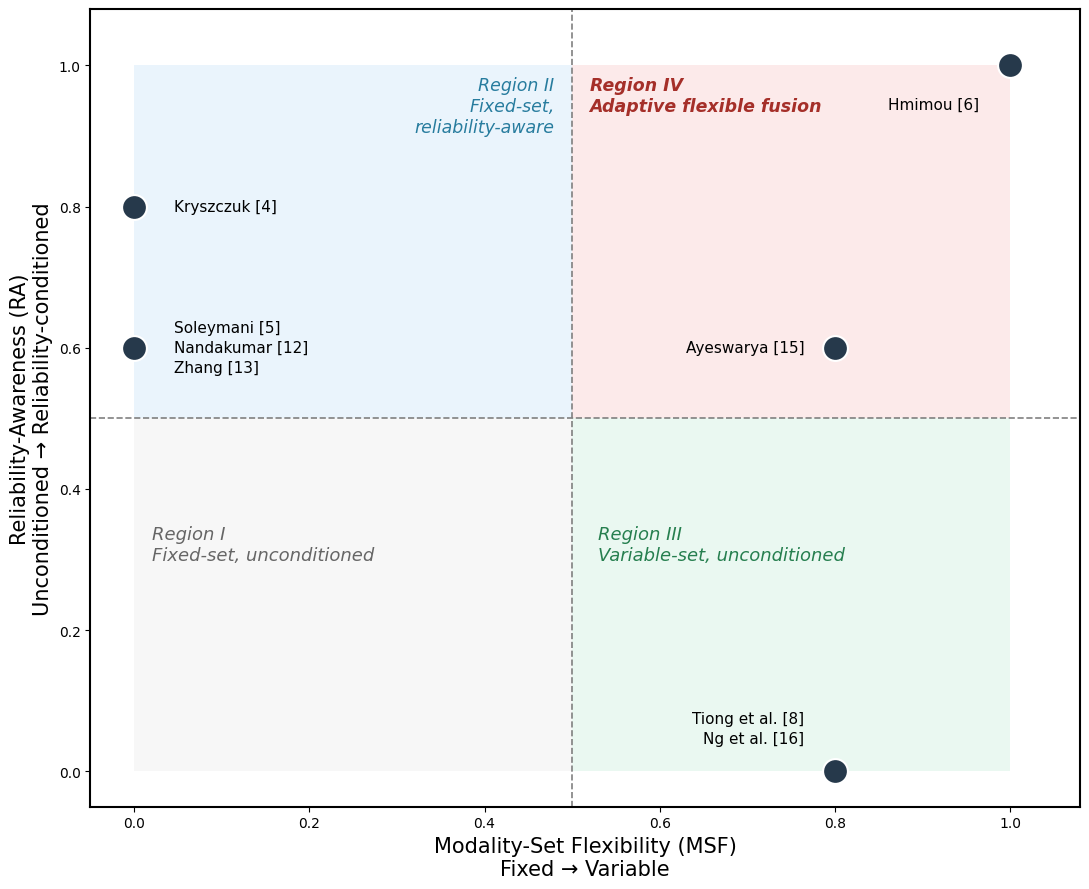

In [5]:
fig, ax = plt.subplots(figsize=(11, 9))

# Define the background colors of the four regions.
cols = {
    "I": "#f7f7f7",
    "II": "#eaf4fc",
    "III": "#eaf8f1",
    "IV": "#fceaea"
}

# Draw the four conceptual regions.
for (x0, y0), k in {
    (0, 0): "I",
    (0, 0.5): "II",
    (0.5, 0): "III",
    (0.5, 0.5): "IV"
}.items():

    ax.add_patch(
        Rectangle(
            (x0, y0),
            0.5,
            0.5,
            facecolor=cols[k],
            edgecolor="none"
        )
    )

# Draw the boundaries between the regions.
ax.axvline(0.5, color="gray", ls="--", lw=1.2)
ax.axhline(0.5, color="gray", ls="--", lw=1.2)

# Group approaches sharing identical coordinates.
groups = {}

for name, p in papers.items():
    key = (round(p["x"], 3), round(p["y"], 3))
    groups.setdefault(key, []).append(name)

# Define label positions to improve readability.
place = {
    (0.8, 0.0): (-0.035, 0.06, "right"),
    (0.8, 0.6): (-0.035, 0.0, "right"),
    (1.0, 1.0): (-0.035, -0.055, "right")
}

# Plot each group of approaches.
for (x, y), names in groups.items():

    ax.scatter(
        x, y,
        s=320,
        color="#26394b",
        edgecolor="white",
        linewidth=1.5,
        zorder=5
    )

    txt = "\n".join(
        f"{n} [{papers[n]['NUM']}]"
        for n in sorted(names, key=lambda k: papers[k]["NUM"])
    )

    dx, dy, ha = place.get(
        (x, y),
        (0.045, 0.0, "left")
    )

    ax.text(
        x + dx,
        y + dy,
        txt,
        fontsize=11,
        ha=ha,
        va="center",
        linespacing=1.4
    )

# Add conceptual region descriptions.
ax.text(
    0.02, 0.30,
    "Region I\nFixed-set, unconditioned",
    fontsize=13,
    style="italic",
    color="#666"
)

ax.text(
    0.48, 0.985,
    "Region II\nFixed-set,\nreliability-aware",
    fontsize=12.5,
    style="italic",
    color="#277c9e",
    ha="right",
    va="top"
)

ax.text(
    0.53, 0.30,
    "Region III\nVariable-set, unconditioned",
    fontsize=13,
    style="italic",
    color="#267f4f"
)

ax.text(
    0.52, 0.985,
    "Region IV\nAdaptive flexible fusion",
    fontsize=12.5,
    style="italic",
    weight="bold",
    color="#a52f29",
    va="top"
)

# Configure axis labels and limits.
ax.set_xlabel(
    "Modality-Set Flexibility (MSF)\nFixed → Variable",
    fontsize=15
)

ax.set_ylabel(
    "Reliability-Awareness (RA)\nUnconditioned → Reliability-conditioned",
    fontsize=15
)

ax.set_xlim(-0.05, 1.08)
ax.set_ylim(-0.05, 1.08)

ticks = [0, 0.2, 0.4, 0.6, 0.8, 1.0]

ax.set_xticks(ticks)
ax.set_yticks(ticks)

# Improve plot frame visibility.
for spine in ax.spines.values():
    spine.set_linewidth(1.5)

plt.tight_layout()

# Display the plot directly.
plt.show()